# Extensión B: t-SNE y por qué un mapa no es una medida

**Materiales desarrollados por Matías Barreto, 2026**

**Tecnicatura Superior en Ciencias de Datos e IA, IFTS N.º 24**
* **Nomenclatura oficial:** Procesamiento de Lenguaje Natural
* **Nombre de trabajo:** Laboratorio de PLN: Analítica, Textos y Cultura

---

## Pregunta

¿Cuánto cambia un mapa de t-SNE si cambiamos un parámetro que no tiene nada que ver con los datos?

## Objetivo

Proyectar los mismos embeddings con t-SNE y distintas perplejidades, y comprobar que la forma del mapa depende de decisiones nuestras.

## Al terminar este cuaderno vamos a poder:

1. Explicar qué hace t-SNE a grandes rasgos y qué parámetro controla.
2. Mostrar que dos mapas del mismo conjunto de datos pueden verse muy distintos.
3. Argumentar por qué las distancias entre grupos, el tamaño de los grupos y los huecos de un mapa de t-SNE no se interpretan como medidas.

## Prerrequisitos reales

* Cuaderno 05 de esta unidad, sección 8 (PCA).

## Recursos y condiciones de ejecución

Local, unos 30 segundos. Usa el modelo de oraciones del cuaderno 04 (470 MB). No usamos UMAP: no está instalado en el entorno de la unidad y no lo verificamos.

## Qué es esencial y qué es opcional

* **Esencial:** Opcional.
* **Opcional:** Todo.

## Producto

Una explicación de cinco líneas sobre qué puede y qué no puede afirmarse viendo un mapa de t-SNE.

## Alcance

28 fragmentos y tres perplejidades. No hay recomendación de valores "correctos".

In [1]:
# Esta extensión vive en extensiones/. Subimos a la carpeta de la unidad para que las rutas relativas funcionen.
import os
from pathlib import Path

if Path.cwd().name == "extensiones":
    os.chdir(Path.cwd().parent)
print("Carpeta de trabajo:", Path.cwd().name)

Carpeta de trabajo: 009_representaciones_semanticas


## 1. La idea

t-SNE (van der Maaten y Hinton, 2008) busca colocar los puntos en el plano de modo que los **vecinos cercanos** del espacio original queden cerca. El parámetro `perplexity` define cuántos vecinos "cuentan" para cada punto; no se deduce de los datos. Con pocos puntos, el valor tiene que ser menor que la cantidad de puntos.

In [2]:
import sys
import importlib.metadata

import numpy as np
import matplotlib.pyplot as plt

from sklearn.manifold import TSNE
from sentence_transformers import SentenceTransformer

import utils

SEMILLA = 42
print("Python:", sys.version.split()[0], "| scikit-learn:", importlib.metadata.version("scikit-learn"), "| semilla:", SEMILLA)

fragmentos = utils.cargar_fragmentos()
juicios = utils.cargar_juicios()
lista_de_ids = list(fragmentos["id"])

# Los mismos 28 fragmentos del cuaderno 05: relevantes totales de C03, C04, C07 y C08.
nombres_de_los_grupos = {"C03": "suicidio", "C04": "cocina", "C07": "poder", "C08": "instrucciones"}
identificadores = []
grupos = []
for id_consulta, nombre in nombres_de_los_grupos.items():
    totales = juicios[(juicios["id_consulta"] == id_consulta) & (juicios["relevancia"] == 2)]
    for identificador in totales["id_fragmento"]:
        if identificador not in identificadores:
            identificadores.append(identificador)
            grupos.append(nombre)

modelo = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")
textos = []
for identificador in identificadores:
    textos.append(fragmentos.loc[fragmentos["id"] == identificador, "texto"].iloc[0])
embeddings = modelo.encode(textos, show_progress_bar=False)
print(len(identificadores), "fragmentos,", embeddings.shape[1], "dimensiones")

Python: 3.12.13 | scikit-learn: 1.9.1 | semilla: 42


28 fragmentos, 384 dimensiones


## 2. Tres perplejidades, los mismos datos

**Decisión previa.** Probamos 5, 10 y 20 y mostramos los tres mapas, sin elegir el que mejor separe los grupos.

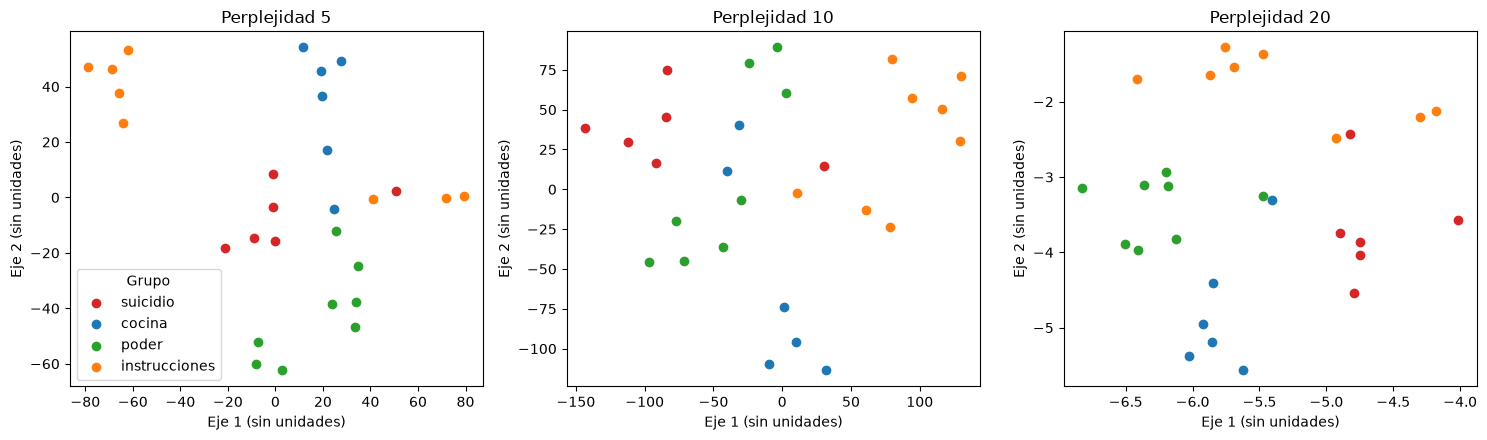

In [3]:
figura, ejes = plt.subplots(1, 3, figsize=(15, 4.5))
perplejidades = [5, 10, 20]
colores = {"suicidio": "tab:red", "cocina": "tab:blue", "poder": "tab:green", "instrucciones": "tab:orange"}

lugar_del_eje = 0
for perplejidad in perplejidades:
    eje = ejes[lugar_del_eje]
    lugar_del_eje += 1
    mapa = TSNE(n_components=2, perplexity=perplejidad, random_state=SEMILLA, init="pca").fit_transform(X=embeddings)
    for nombre_del_grupo, color in colores.items():
        lugares = []
        lugar = 0
        for grupo in grupos:
            if grupo == nombre_del_grupo:
                lugares.append(lugar)
            lugar += 1
        eje.scatter(mapa[lugares, 0], mapa[lugares, 1], color=color, label=nombre_del_grupo)
    eje.set_title(f"Perplejidad {perplejidad}")
    eje.set_xlabel("Eje 1 (sin unidades)")
    eje.set_ylabel("Eje 2 (sin unidades)")

ejes[0].legend(title="Grupo")
plt.tight_layout()
plt.show()

**Lectura.**

* **Observación.** Con perplejidad 5, el grupo *instrucciones* se parte en dos conjuntos separados y los otros tres grupos se mezclan; con 20, los cuatro grupos aparecen más reconocibles (*instrucciones* arriba, *poder* a la izquierda, *suicidio* a la derecha, *cocina* abajo). Los números de los ejes cambian de escala: de -80 a 80 con 5, de -150 a 130 con 10 y de -7 a -4 con 20.
* **Interpretación posible.** La forma del mapa depende de un parámetro que fijamos nosotros. Que un grupo se parta en dos o se junte no es una propiedad de los datos.
* **Límite.** Son 28 puntos. Con más datos las diferencias entre perplejidades suelen ser menos extremas, pero no desaparecen.

### ✎ Para pensar

* ¿Qué grupos quedan siempre juntos y cuáles cambian de vecinos según la perplejidad?
* Si dos grupos están lejos en un mapa, ¿podemos decir que son más distintos que otros dos que están más cerca? ¿Por qué no?
* ¿Qué haríamos para saber si una separación visual refleja algo real? (Pista: la evaluación del cuaderno 05 no usa mapas.)

> _(Escriban acá.)_

## 3. Cierre

Un mapa de t-SNE sirve para **explorar** y para **formular hipótesis** sobre qué fragmentos son vecinos. No sirve como evidencia de que una representación sea buena, ni para comparar tamaños o distancias entre grupos. Para eso hacen falta medidas definidas de antemano.